In [1]:
import os
import sys
import PIL
from PIL import Image
import numpy as np
import torch
from torchvision import transforms

sys.path.append("../unisal/")
import unisal

In [10]:
def preprocess(img):
    img = np.ascontiguousarray(img[:, :, ::-1])
    print(img.shape)
    preproc_cfg = {
        "out_size": [288, 384],
        "rgb_mean": (0.485, 0.456, 0.406),
        "rgb_std": (0.229, 0.224, 0.225),
    }
    transformations = [
        transforms.ToPILImage(),
        transforms.Resize(preproc_cfg["out_size"], interpolation=PIL.Image.LANCZOS),
        transforms.ToTensor(),
    ]
    if "rgb_mean" in preproc_cfg:
        transformations.append(
            
            transforms.Normalize(preproc_cfg["rgb_mean"], preproc_cfg["rgb_std"])
        )
    processing = transforms.Compose(transformations)
    tensor = processing(img)
    print('tensor',tensor.shape)
    return tensor


def normalize_map(s_map):
    # normalize the salience map (as done in MIT code)
    norm_s_map = (s_map - np.min(s_map)) / ((np.max(s_map) - np.min(s_map)))
    return norm_s_map

In [3]:
unisal_model = unisal.model.UNISAL()
unisal_model.load_state_dict(torch.load("../models/unisal.pth"))

model_traced = torch.jit.trace(
    unisal_model.eval().to("cuda:0"), torch.rand(1, 1, 3, 288, 384).to("cuda:0")
).to("cuda:0")
# torch.jit.save(model_traced, "../models/unisal_jit_traced.pth")

/home/cp/miniconda3/envs/access/lib/python3.9/site-packages/torch/functional.py:507: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3549.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/home/cp/Documents/Libra/access/eht_gaze_prediction/notebooks/../unisal/unisal/model.py:434: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  static = x.shape[1] == 1 or self.sources == ('SALICON',)
/home/cp/miniconda3/envs/access/lib/python3.9/site-packages/torch/nn/modules/conv.py:456: UserWarning: Applied workaround for CuDNN issue, install nvrtc.so (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:80.)
  return F.conv2d(input

In [3]:
sal_model = torch.jit.load("../models/unisal_jit_traced.pth")
sal_model.eval()

RecursiveScriptModule(
  original_name=UNISAL
  (cnn): RecursiveScriptModule(
    original_name=MobileNetV2
    (features): RecursiveScriptModule(
      original_name=Sequential
      (0): RecursiveScriptModule(
        original_name=Sequential
        (0): RecursiveScriptModule(original_name=Conv2d)
        (1): RecursiveScriptModule(original_name=BatchNorm2d)
        (2): RecursiveScriptModule(original_name=ReLU6)
      )
      (1): RecursiveScriptModule(
        original_name=InvertedResidual
        (conv): RecursiveScriptModule(
          original_name=Sequential
          (0): RecursiveScriptModule(original_name=Conv2d)
          (1): RecursiveScriptModule(original_name=BatchNorm2d)
          (2): RecursiveScriptModule(original_name=ReLU6)
          (3): RecursiveScriptModule(original_name=Conv2d)
          (4): RecursiveScriptModule(original_name=BatchNorm2d)
        )
      )
      (2): RecursiveScriptModule(
        original_name=InvertedResidual
        (conv): RecursiveScrip

In [4]:
torch.save(sal_model.state_dict(), "../models/testunisal.pth")

In [6]:
img.shape

torch.Size([1, 1, 3, 288, 384])

In [11]:
imarray = np.random.rand(288, 384, 3) * 255
img = imarray.astype(np.uint8)
img = preprocess(img)
print(img.shape)
img = img.unsqueeze(0).unsqueeze(0).float().to("cuda:0")
sal_map = model_traced(img)

(288, 384, 3)
tensor torch.Size([3, 288, 384])
torch.Size([3, 288, 384])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


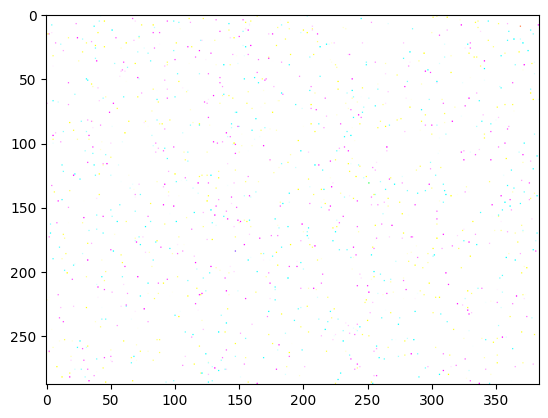

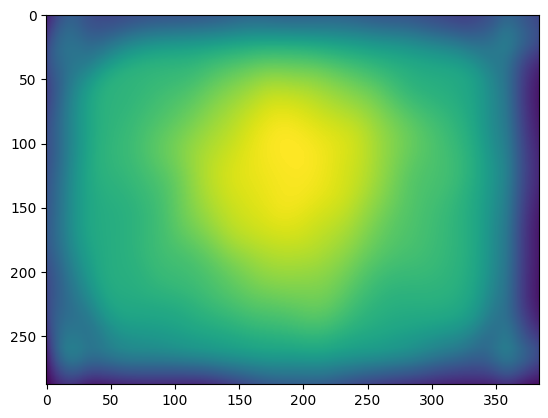

In [5]:
import matplotlib.pyplot as plt

plt.imshow(imarray)
plt.show()
plt.imshow(sal_map.to("cpu").squeeze().detach().numpy())
plt.show()

In [ ]:
for i, child in enumerate(sal_model.children()):
    print(i, child)

In [50]:
import torch
import torch.nn as nn


class CombinedModel(nn.Module):
    def __init__(self, model_a, freeze_up_to_layer):
        super(CombinedModel, self).__init__()

        # Freeze Model A up to the specified layer
        self.frozen_layers = nn.Sequential(
            *list(model_a.children())[:freeze_up_to_layer]
        )
        for param in self.frozen_layers.parameters():
            param.requires_grad = False

        # Get the output shape of the last frozen layer
        with torch.no_grad():
            imarray = np.random.rand(288, 384, 3) * 255
            img = imarray.astype(np.uint8)
            img = preprocess(img)
            img = img.unsqueeze(0).float()
            # Adjust input shape as needed
            frozen_output = self.frozen_layers(img)

        # Calculate the flattened size
        flattened_size = frozen_output.numel() // frozen_output.size(0)

        # Define Model B layers
        self.flatten = nn.Flatten()
        self.dense = nn.Linear(flattened_size, 10)

    def forward(self, x):
        x = self.frozen_layers(x)
        x = self.flatten(x)
        x = self.dense(x)
        return x


# Load pre-trained Model A
model_a = torch.load("../models/unisal.pt")
model_a.eval()
model_a = model_a.to("cpu")

# Create the combined model
freeze_up_to_layer = 8  # Freeze up to conv2 layer
combined_model = CombinedModel(model_a, freeze_up_to_layer)

# Now you can train the combined model
# The frozen layers from Model A will not be updated during training

TypeError: conv2d() received an invalid combination of arguments - got (tuple, Parameter, NoneType, tuple, tuple, tuple, int), but expected one of:
 * (Tensor input, Tensor weight, Tensor bias, tuple of ints stride, tuple of ints padding, tuple of ints dilation, int groups)
      didn't match because some of the arguments have invalid types: (!tuple of (Tensor, Tensor, Tensor)!, !Parameter!, !NoneType!, !tuple of (int, int)!, !tuple of (int, int)!, !tuple of (int, int)!, int)
 * (Tensor input, Tensor weight, Tensor bias, tuple of ints stride, str padding, tuple of ints dilation, int groups)
      didn't match because some of the arguments have invalid types: (!tuple of (Tensor, Tensor, Tensor)!, !Parameter!, !NoneType!, !tuple of (int, int)!, !tuple of (int, int)!, !tuple of (int, int)!, int)
